In [1]:
import pandas as pd
import re
from pathlib import Path

# Leer las evidencias generadas por Spark
ruta = Path("../docs/evidencias/escalabilidad/resumen_benchmark_nacional.txt")
texto = ruta.read_text(encoding="utf-8")

resultados = []

for factor in [1, 10, 100]:
    bloque = texto.split(f"========== ESCALA {factor}X ==========")[1]
    bloque = bloque.split("========== ESCALA")[0]
    bloque = bloque.split("LIMITACIONES:")[0]

    registros = int(
        re.search(r"Registros verificados:\s*(\d+)", bloque).group(1)
    )

    mediana = float(
        re.search(r"Mediana:\s*([\d.]+)", bloque).group(1)
    )

    ejecuciones = re.findall(
        r"Ejecucion \d+:\s*([\d.]+) segundos", bloque
    )

    resultados.append({
        "Escala": f"{factor}x",
        "Registros": registros,
        "Ejecucion 1": float(ejecuciones[0]),
        "Ejecucion 2": float(ejecuciones[1]),
        "Ejecucion 3": float(ejecuciones[2]),
        "Mediana (s)": mediana
    })

df = pd.DataFrame(resultados)

display(df)

,Escala,Registros,Ejecucion 1,Ejecucion 2,Ejecucion 3,Mediana (s)
0,1x,142139,1.895,0.913,0.606,0.913
1,10x,1421390,1.986,0.999,0.869,0.999
2,100x,14213900,3.561,2.746,2.158,2.746


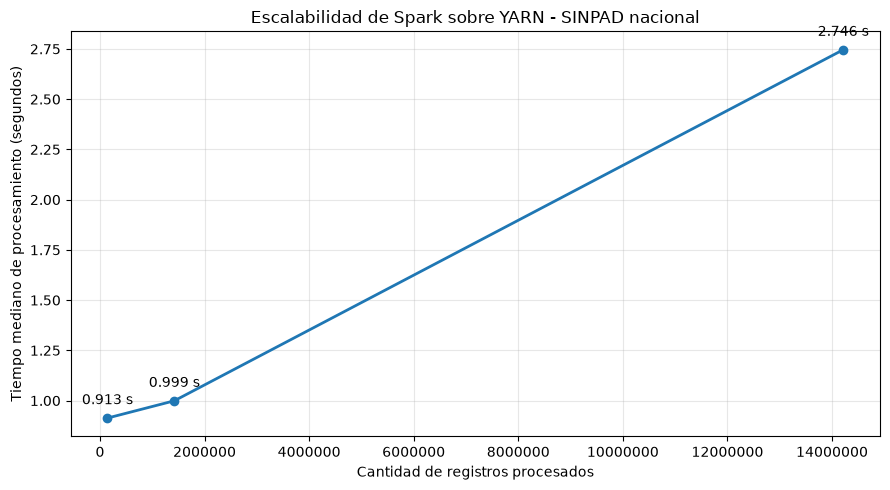

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    df["Registros"],
    df["Mediana (s)"],
    marker="o",
    linewidth=2
)

for x, y in zip(df["Registros"], df["Mediana (s)"]):
    plt.annotate(
        f"{y:.3f} s",
        (x, y),
        xytext=(0, 10),
        textcoords="offset points",
        ha="center"
    )

plt.title("Escalabilidad de Spark sobre YARN - SINPAD nacional")
plt.xlabel("Cantidad de registros procesados")
plt.ylabel("Tiempo mediano de procesamiento (segundos)")
plt.grid(True, alpha=0.3)
plt.ticklabel_format(style="plain", axis="x")
plt.tight_layout()

plt.savefig(
    "../docs/evidencias/escalabilidad/tiempo_vs_registros.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

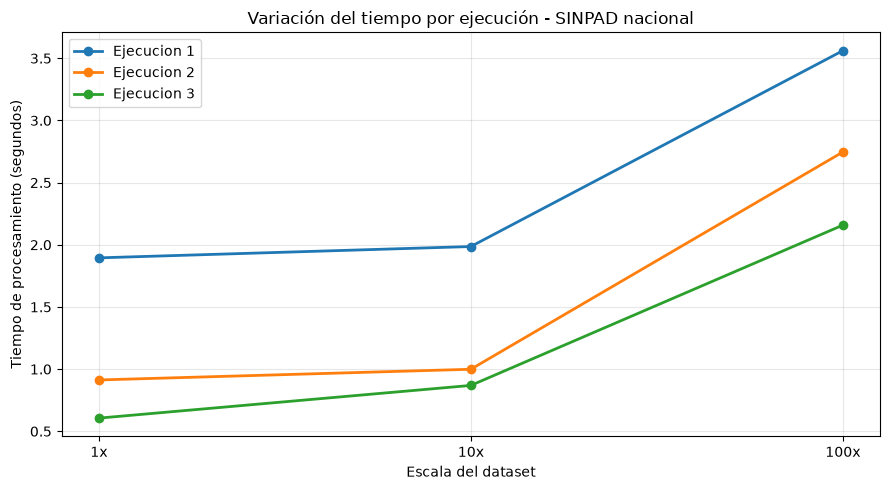

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

escalas = df["Escala"]

for columna in ["Ejecucion 1", "Ejecucion 2", "Ejecucion 3"]:
    plt.plot(
        escalas,
        df[columna],
        marker="o",
        linewidth=2,
        label=columna
    )

plt.title("Variación del tiempo por ejecución - SINPAD nacional")
plt.xlabel("Escala del dataset")
plt.ylabel("Tiempo de procesamiento (segundos)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../docs/evidencias/escalabilidad/tiempos_por_ejecucion.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

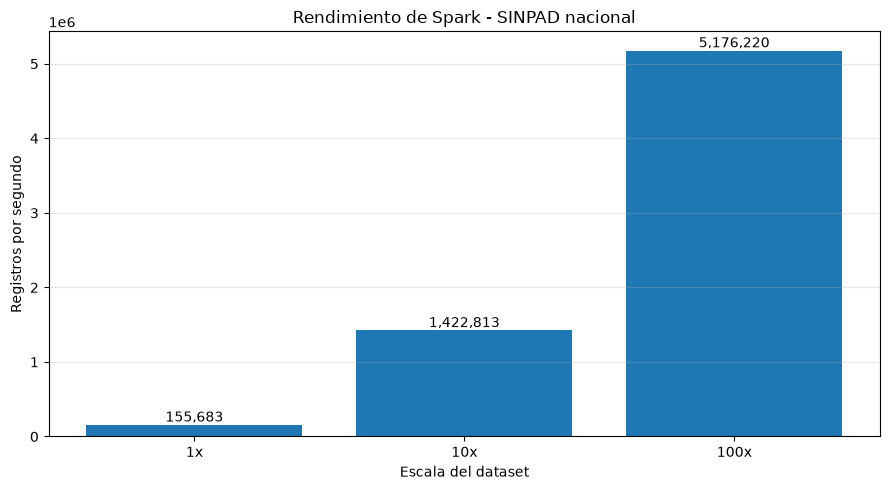

,Escala,Registros,Mediana (s),Registros por segundo
0,1x,142139,0.913,1.556835e+05
1,10x,1421390,0.999,1.422813e+06
2,100x,14213900,2.746,5.176220e+06


In [4]:
import matplotlib.pyplot as plt

df["Registros por segundo"] = (
    df["Registros"] / df["Mediana (s)"]
)

plt.figure(figsize=(9, 5))

plt.bar(
    df["Escala"],
    df["Registros por segundo"]
)

for i, valor in enumerate(df["Registros por segundo"]):
    plt.text(
        i,
        valor,
        f"{valor:,.0f}",
        ha="center",
        va="bottom"
    )

plt.title("Rendimiento de Spark - SINPAD nacional")
plt.xlabel("Escala del dataset")
plt.ylabel("Registros por segundo")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "../docs/evidencias/escalabilidad/registros_por_segundo.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

display(df[["Escala", "Registros", "Mediana (s)", "Registros por segundo"]])

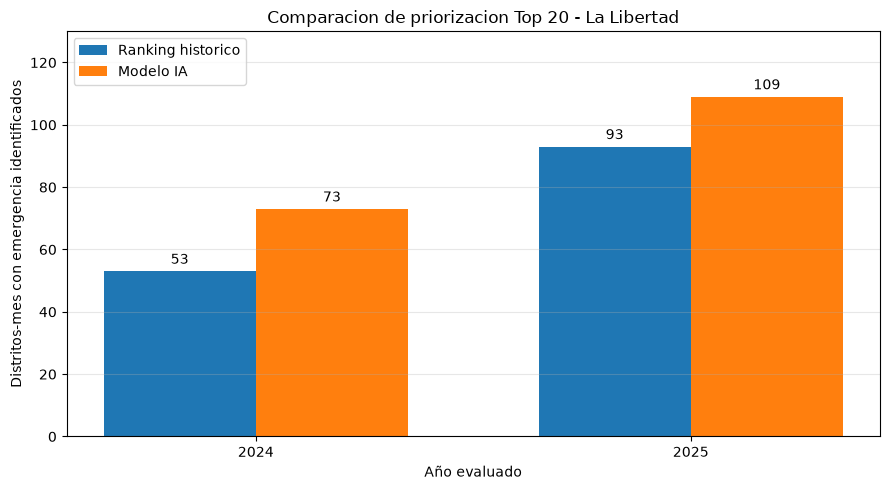

,Año,Historico,IA
0,2024,53,73
1,2025,93,109


In [5]:
import re
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

base = Path("../resultados/verificacion_modelo")

def obtener_top20(archivo, titulo):
    texto = (base / archivo).read_text()
    seccion = texto.split(f"=== {titulo} ===")[1]

    for linea in seccion.splitlines():
        if re.match(r"^20\s*\|", linea.strip()):
            valores = [v.strip() for v in linea.split("|")]
            return int(valores[2])

    raise ValueError(f"No se encontro Top 20 en {archivo}")

datos = []

for anio, archivo in [
    (2024, "comparacion_ranking_historico.log"),
    (2025, "evaluacion_final_2025.log")
]:
    datos.append({
        "Año": anio,
        "Historico": obtener_top20(archivo, "RANKING HISTORICO"),
        "IA": obtener_top20(archivo, "RANKING MENSUAL DE DISTRITOS")
    })

comparacion = pd.DataFrame(datos)

x = list(range(len(comparacion)))
ancho = 0.35

plt.figure(figsize=(9, 5))

b1 = plt.bar(
    [i - ancho/2 for i in x],
    comparacion["Historico"],
    ancho,
    label="Ranking historico"
)

b2 = plt.bar(
    [i + ancho/2 for i in x],
    comparacion["IA"],
    ancho,
    label="Modelo IA"
)

plt.bar_label(b1, padding=3)
plt.bar_label(b2, padding=3)

plt.xticks(x, comparacion["Año"])
plt.title("Comparacion de priorizacion Top 20 - La Libertad")
plt.xlabel("Año evaluado")
plt.ylabel("Distritos-mes con emergencia identificados")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.ylim(0, 130)
plt.tight_layout()

destino = Path("../docs/evidencias/linea_base")
destino.mkdir(parents=True, exist_ok=True)

plt.savefig(
    destino / "comparacion_top20_2024_2025.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()
display(comparacion)

## Evaluación de la línea base del negocio

### Indicador: Cobertura de emergencias Top 20

El indicador mide qué porcentaje de los distrito-mes
con emergencia se identifica al priorizar 20 distritos
mensualmente.

**Fórmula:**

Cobertura Top 20 = (Casos positivos identificados
en el Top 20 / Total de casos positivos) × 100

### Resultados

| Año | Histórico | Modelo IA |
|---|---|---|
| 2024 | 31.18 % | 42.94 % |
| 2025 | 31.10 % | 36.45 % |

### Decisión que apoya

Generar mensualmente una lista de distritos que
podrían requerir mayor revisión preventiva.

### Responsable propuesto

Personal técnico de gestión del riesgo de desastres,
con validación de las autoridades correspondientes.

### Limitaciones

El ranking histórico es una referencia académica,
no el procedimiento oficial de INDECI.

No se midieron tiempos reales de priorización de INDECI.

La evaluación de 2025 no fue completamente ciega.